# Assignment: Feature Engineering (Weeks 4 and 5) - Bruno Cavagnaro

**GRAD 50800 - Data Analytics**

Data: *Responses to Educational Disruption Survey* (REDS), United Arab Emirates, Grade 8 students, their teachers and their school heads (Dec 2020 - Jul 2021).

**Label:** `IS18C_plan_capacity`, the student's capacity to plan the completion of schoolwork (1 = Decreased, 2 = Did not change, 3 = Increased).

> **How to run:** the three CSV files are in `data/` next to this notebook; run all cells. Columns are found by their codebook prefix (for example `IS14A`).

## 0. Setup

In [12]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.decomposition import PCA, FactorAnalysis
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import StratifiedKFold, GridSearchCV, train_test_split, cross_val_score
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, balanced_accuracy_score
import statsmodels.api as sm

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 508

DATA_DIR = Path("data")
FILES = {
    "student": "student_questionnaire_data.csv",
    "teacher": "teacher_questionnaire_data.csv",
    "school":  "school_head_questionnaire_data.csv",
}

In [13]:
def find_file(name: str) -> Path:
    # Look for the file in DATA_DIR, then in a few other likely places
    for d in [DATA_DIR, Path("."), Path("..") / "data"]:
        p = d / name
        if p.exists():
            return p
    raise FileNotFoundError(f"Could not find '{name}'. Put it in {DATA_DIR.resolve()}")

def col(df: pd.DataFrame, prefix: str) -> str:
    # Return the column whose name equals or starts with a codebook prefix
    if prefix in df.columns:
        return prefix
    hits = [c for c in df.columns if c.upper().startswith(prefix.upper())]
    if not hits:
        raise KeyError(f"No column starting with '{prefix}'")
    return min(hits, key=len)

student = pd.read_csv(find_file(FILES["student"]))
teacher = pd.read_csv(find_file(FILES["teacher"]))
school  = pd.read_csv(find_file(FILES["school"]))

for name, df in [("Student", student), ("Teacher", teacher), ("School", school)]:
    print(f"{name:8s}: {df.shape[0]:>6,} rows x {df.shape[1]:>3} cols")

Student :  2,988 rows x  28 cols
Teacher :  2,661 rows x   6 cols
School  :    172 rows x   7 cols


In [14]:
display(student.head()); display(teacher.head()); display(school.head())

,IDSTUD,IDSCHOOL,TOTWGTS,IS18C_plan_capacity,ASDAGE,SEX_female,IS34_lang,prnt_ed_M,IS17G_miss_meals,IS01_prop_sch_time,IS09_comm_modes,IS21_teach_sup,IS18E_adult_help,IS14A,IS14C,IS14K,IS17A,IS17C,IS17E,IS25A,IS25B,IS25C,IS25D,IS25E,IS25F,IS25G,IS25H,IS25J
0,10010101,1001,27.810256,2.0,13.00,0,1,NaN,3.0,1.0,2.0,NaN,2.0,3.0,2.0,NaN,4.0,2.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,10010102,1001,27.810256,3.0,12.67,0,1,3.0,2.0,1.0,0.0,2.5,3.0,1.0,3.0,3.0,4.0,1.0,4.0,3.0,2.0,2.0,3.0,3.0,2.0,3.0,3.0,3.0
2,10010103,1001,27.810256,1.0,13.42,0,1,NaN,1.0,5.0,2.0,NaN,2.0,3.0,3.0,NaN,4.0,4.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,10010104,1001,27.810256,2.0,13.83,0,1,3.5,2.0,1.0,4.0,3.0,3.0,2.0,2.0,3.0,3.0,3.0,1.0,3.0,2.0,3.0,3.0,3.0,3.0,3.0,4.0,2.0
4,10010106,1001,27.810256,2.0,13.42,0,1,4.0,1.0,1.0,3.0,3.0,3.0,3.0,2.0,1.0,4.0,2.0,1.0,2.0,2.0,2.0,3.0,2.0,1.0,3.0,3.0,2.0


,IDSCHOOL,IDTEACH,IT05F_indiv,IT06A_teach_qual,IT06D_indep,IT25_yrs_exp
0,1001,100101,2.0,3.0,3.0,4.0
1,1001,100102,4.0,3.0,3.0,6.0
2,1001,100103,2.0,2.0,3.0,4.0
3,1001,100104,3.0,3.0,3.0,4.0
4,1001,100105,5.0,4.0,4.0,4.0


,IDSCHOOL,IP13D_prnt_sup,IP21_remote_prep,IP34_locale_size,IP34A_public,IP1G35C_prop_disadvan,IP03_tech
0,1001,2.0,3.0,2.0,1.0,1.0,2
1,1002,3.0,4.0,3.0,1.0,3.0,2
2,1003,2.0,4.0,1.0,1.0,1.0,2
3,1004,3.0,4.0,3.0,1.0,3.0,2
4,1005,3.0,4.0,1.0,1.0,1.0,2


In [15]:
# Survey files often code "not administered / omitted" as 9, 99, 999...
# Show each column's maximum so any leftover missing-value codes are easy to spot.
for name, df in [("Student", student), ("Teacher", teacher), ("School", school)]:
    print(name, df.select_dtypes("number").max().to_dict(), "\n")

Student {'IDSTUD': 12000120.0, 'IDSCHOOL': 1200.0, 'TOTWGTS': 115.9726979800853, 'IS18C_plan_capacity': 3.0, 'ASDAGE': 17.67, 'SEX_female': 1.0, 'IS34_lang': 4.0, 'prnt_ed_M': 5.0, 'IS17G_miss_meals': 4.0, 'IS01_prop_sch_time': 5.0, 'IS09_comm_modes': 4.0, 'IS21_teach_sup': 4.0, 'IS18E_adult_help': 3.0, 'IS14A': 4.0, 'IS14C': 4.0, 'IS14K': 4.0, 'IS17A': 4.0, 'IS17C': 4.0, 'IS17E': 4.0, 'IS25A': 4.0, 'IS25B': 4.0, 'IS25C': 4.0, 'IS25D': 4.0, 'IS25E': 4.0, 'IS25F': 4.0, 'IS25G': 4.0, 'IS25H': 4.0, 'IS25J': 4.0} 

Teacher {'IDSCHOOL': 1200.0, 'IDTEACH': 120013.0, 'IT05F_indiv': 5.0, 'IT06A_teach_qual': 4.0, 'IT06D_indep': 4.0, 'IT25_yrs_exp': 6.0} 

School {'IDSCHOOL': 1200.0, 'IP13D_prnt_sup': 3.0, 'IP21_remote_prep': 4.0, 'IP34_locale_size': 5.0, 'IP34A_public': 1.0, 'IP1G35C_prop_disadvan': 5.0, 'IP03_tech': 2.0} 



---
## Q1. Which ID(s) are present in each dataset?

In [16]:
ID_COLS = ["IDSTUD", "IDSCHOOL", "IDTEACH"]
id_table = pd.DataFrame(
    {name: [c in df.columns for c in ID_COLS] for name, df in
     [("Student", student), ("Teacher", teacher), ("School", school)]},
    index=ID_COLS)
display(id_table)

print("Unique IDSTUD in Student:", student["IDSTUD"].nunique(), "| rows:", len(student))
for name, df in [("Student", student), ("Teacher", teacher), ("School", school)]:
    print(f"{name:8s} unique IDSCHOOL: {df['IDSCHOOL'].nunique():>4}  | rows per school (median): "
          f"{df.groupby('IDSCHOOL').size().median():.0f}")

stu_sch, tch_sch, sch_sch = (set(d["IDSCHOOL"]) for d in (student, teacher, school))
print("\nStudent schools without teacher data:", len(stu_sch - tch_sch))
print("Student schools without school-head data:", len(stu_sch - sch_sch))

,Student,Teacher,School
IDSTUD,True,False,False
IDSCHOOL,True,True,True
IDTEACH,False,True,False


Unique IDSTUD in Student: 2988 | rows: 2988
Student  unique IDSCHOOL:  171  | rows per school (median): 19
Teacher  unique IDSCHOOL:  181  | rows per school (median): 15
School   unique IDSCHOOL:  172  | rows per school (median): 1

Student schools without teacher data: 0
Student schools without school-head data: 7


**Answer.**

| Dataset | `IDSTUD` | `IDSCHOOL` | `IDTEACH` | Rows |
|---|---|---|---|---|
| Student | ✔ (unique, 2,988) | ✔ (171 schools) | – | 2,988 |
| Teacher | – | ✔ (181 schools) | ✔ (unique, 2,661) | 2,661 |
| School Head | – | ✔ (172 schools, one row each) | – | 172 |

`IDSCHOOL` is the only key shared by all three files. The Teacher file also has its own teacher ID (`IDTEACH`), but no file links a student to a particular teacher. That is why the teacher data has to be aggregated to the school level (Q2). All 171 student schools appear in the Teacher file. **7 student schools have no School Head record**, so their school variables will be missing after the merge. The Teacher file also has 10 schools with no sampled students; these drop out in a left join on the Student file.

---
## Q2. Aggregate the Teacher data within each school

In [17]:
T_QUAL  = col(teacher, "IT06A")   # teacher maintained quality of teaching (1-4)
T_INDEP = col(teacher, "IT06D")   # materials let students work independently (1-4)

teacher[[T_QUAL, T_INDEP]].describe().T

,count,mean,std,min,25%,50%,75%,max
IT06A_teach_qual,2584.0,3.145511,0.772467,1.0,3.0,3.0,4.0,4.0
IT06D_indep,2578.0,3.359969,0.586337,1.0,3.0,3.0,4.0,4.0


In [18]:
per_school = teacher.groupby("IDSCHOOL").agg(
    n_teachers=(T_QUAL, "size"),
    qual_mean=(T_QUAL, "mean"), qual_median=(T_QUAL, "median"), qual_sd=(T_QUAL, "std"),
    indep_mean=(T_INDEP, "mean"), indep_median=(T_INDEP, "median"))
display(per_school.describe().T.round(2))

# How much information does each statistic keep?
print("Distinct values  - qual mean:", per_school["qual_mean"].nunique(),
      "| qual median:", per_school["qual_median"].nunique())

,count,mean,std,min,25%,50%,75%,max
n_teachers,181.0,14.70,4.61,2.00,11.00,15.00,19.00,20.00
qual_mean,181.0,3.14,0.33,1.88,3.00,3.21,3.37,3.67
qual_median,181.0,3.13,0.45,2.00,3.00,3.00,3.00,4.00
qual_sd,181.0,0.70,0.17,0.00,0.59,0.69,0.78,1.33
indep_mean,181.0,3.35,0.19,2.88,3.21,3.33,3.47,3.85
indep_median,181.0,3.28,0.43,3.00,3.00,3.00,3.50,4.00


Distinct values  - qual mean: 88 | qual median: 5


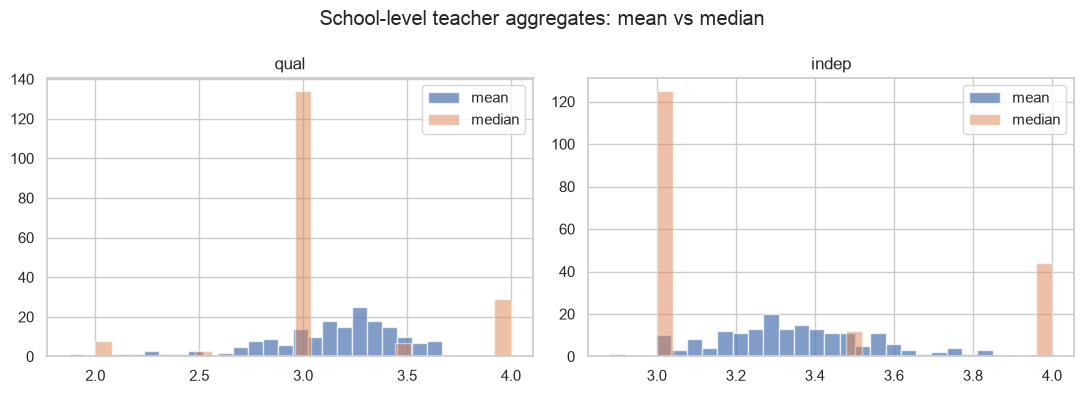

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (m, md_) in zip(axes, [("qual_mean", "qual_median"), ("indep_mean", "indep_median")]):
    ax.hist(per_school[m].dropna(), bins=25, alpha=.7, label="mean")
    ax.hist(per_school[md_].dropna(), bins=25, alpha=.5, label="median")
    ax.set_title(m.split("_")[0]); ax.legend()
plt.suptitle("School-level teacher aggregates: mean vs median"); plt.tight_layout(); plt.show()

In [20]:
teacher_agg = (teacher.groupby("IDSCHOOL")
               .agg(T_n_teachers=(T_QUAL, "size"),
                    T_teach_qual_mean=(T_QUAL, "mean"),
                    T_indep_mat_mean=(T_INDEP, "mean"))
               .reset_index())
teacher_agg.head()

,IDSCHOOL,T_n_teachers,T_teach_qual_mean,T_indep_mat_mean
0,1001,20,3.250000,3.200000
1,1002,20,3.000000,3.157895
2,1003,9,3.375000,3.000000
3,1004,16,3.266667,3.400000
4,1005,17,3.058824,2.882353


**Columns chosen.**
* `IT06A_teach_qual`: whether the teacher kept up the quality of teaching. If teaching stayed good, students had better instruction to organise their work around.
* `IT06D_indep`: whether the materials let students work on their own. This is the teacher-side counterpart of the outcome, since a student who can work independently has to plan their own schoolwork.

**Summary statistic: the school mean** (plus the number of responding teachers, `T_n_teachers`).
1. Both items are 4-point agree/disagree scales, and most teachers answer 3 ("agree"). The school **median** is therefore almost always 3. Across 181 schools it takes only **5 distinct values**, compared with **88** for the mean, so the median would erase most differences between schools (see the histograms above).
2. Schools have a median of **15 responding teachers** (range 2-20). This is enough for the mean to be a stable estimate of the *average* teaching experience a student in that school gets, which is the construct that should matter for a student exposed to all of their teachers.
3. The usual reason to prefer the median, robustness to outliers, carries little weight here: the items are bounded between 1 and 4, so one teacher cannot pull the mean far.

The count is kept because means based on 2-3 teachers are noisier. It could also serve as a reliability weight.

---
## Q3. Merge Student + Teacher aggregate + School data

In [21]:
merged = (student
          .merge(teacher_agg, on="IDSCHOOL", how="left", validate="many_to_one")
          .merge(school,
                 on="IDSCHOOL", how="left", validate="many_to_one",
                 suffixes=("", "_SCH")))

assert len(merged) == len(student), "merge duplicated students"
print(f"Merged dataset: {merged.shape[0]:,} rows x {merged.shape[1]} columns")
print("Students with no teacher aggregate:", merged["T_teach_qual_mean"].isna().sum())
merged.head()

Merged dataset: 2,988 rows x 37 columns
Students with no teacher aggregate: 0


,IDSTUD,IDSCHOOL,TOTWGTS,IS18C_plan_capacity,ASDAGE,SEX_female,IS34_lang,prnt_ed_M,IS17G_miss_meals,IS01_prop_sch_time,IS09_comm_modes,IS21_teach_sup,IS18E_adult_help,IS14A,IS14C,IS14K,IS17A,IS17C,IS17E,IS25A,IS25B,IS25C,IS25D,IS25E,IS25F,IS25G,IS25H,IS25J,T_n_teachers,T_teach_qual_mean,T_indep_mat_mean,IP13D_prnt_sup,IP21_remote_prep,IP34_locale_size,IP34A_public,IP1G35C_prop_disadvan,IP03_tech
0,10010101,1001,27.810256,2.0,13.00,0,1,NaN,3.0,1.0,2.0,NaN,2.0,3.0,2.0,NaN,4.0,2.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20,3.25,3.2,2.0,3.0,2.0,1.0,1.0,2.0
1,10010102,1001,27.810256,3.0,12.67,0,1,3.0,2.0,1.0,0.0,2.5,3.0,1.0,3.0,3.0,4.0,1.0,4.0,3.0,2.0,2.0,3.0,3.0,2.0,3.0,3.0,3.0,20,3.25,3.2,2.0,3.0,2.0,1.0,1.0,2.0
2,10010103,1001,27.810256,1.0,13.42,0,1,NaN,1.0,5.0,2.0,NaN,2.0,3.0,3.0,NaN,4.0,4.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20,3.25,3.2,2.0,3.0,2.0,1.0,1.0,2.0
3,10010104,1001,27.810256,2.0,13.83,0,1,3.5,2.0,1.0,4.0,3.0,3.0,2.0,2.0,3.0,3.0,3.0,1.0,3.0,2.0,3.0,3.0,3.0,3.0,3.0,4.0,2.0,20,3.25,3.2,2.0,3.0,2.0,1.0,1.0,2.0
4,10010106,1001,27.810256,2.0,13.42,0,1,4.0,1.0,1.0,3.0,3.0,3.0,3.0,2.0,1.0,4.0,2.0,1.0,2.0,2.0,2.0,3.0,2.0,1.0,3.0,3.0,2.0,20,3.25,3.2,2.0,3.0,2.0,1.0,1.0,2.0


**Answer.** I used left joins on `IDSCHOOL`, keeping the Student file as the base. Each student is the unit of analysis, and the school-level teacher means and school-head answers are repeated for every student in that school. `validate="many_to_one"` checks that no student row was duplicated.

**The merged dataset has 2,988 rows and 37 columns**: 28 student columns + 3 teacher aggregates + 6 school-head columns (`IDSCHOOL` appears once). Every student has teacher aggregates. The students in the 7 schools without a School Head record (~5-6% of rows) are missing all school-head variables.

---
## Q4. Initial analysis

### 4.1 Define feature groups (codebook)

In [22]:
LABEL = col(merged, "IS18C")            # works for IS18C_plan_capacity or IS18C_inc_plan_capacity
WEIGHT = "TOTWGTS" if "TOTWGTS" in merged.columns else None

DIFF_CODES = ["IS14A", "IS14C", "IS14K", "IS17A", "IS17C", "IS17E",
              "IS25A", "IS25B", "IS25C", "IS25D", "IS25E", "IS25F", "IS25G", "IS25H", "IS25J"]
DIFF = [col(merged, c) for c in DIFF_CODES]

STUDENT_X = [col(merged, c) for c in ["ASDAGE", "SEX", "IS34", "prnt_ed", "IS17G", "IS01",
                                      "IS09", "IS21", "IS18E"]]
TEACHER_X = ["T_n_teachers", "T_teach_qual_mean", "T_indep_mat_mean"]
SCHOOL_X = [col(merged, c) for c in ["IP34_", "IP34A", "IP03", "IP1G35C", "IP13D", "IP21"]]
NOMINAL = [col(merged, "IS34")]          # language at home: unordered

ANALYSIS = [LABEL] + STUDENT_X + DIFF + TEACHER_X + SCHOOL_X
print("Label:", LABEL, "| weight:", WEIGHT)
print(len(ANALYSIS), "analysis columns")

Label: IS18C_plan_capacity | weight: TOTWGTS
34 analysis columns


### 4.2 Missing data

,% missing,group
IS25H,7.5,difficulty
IS25G,7.3,difficulty
IS25D,7.3,difficulty
IS25F,7.3,difficulty
IS25J,7.3,difficulty
IS25E,7.3,difficulty
IS25C,7.2,difficulty
IS25B,7.1,difficulty
IS18C_plan_capacity,6.9,label
IP1G35C_prop_disadvan,6.8,school


Complete cases: 2,245 of 2,988 (75.1%)
Label missing: 205


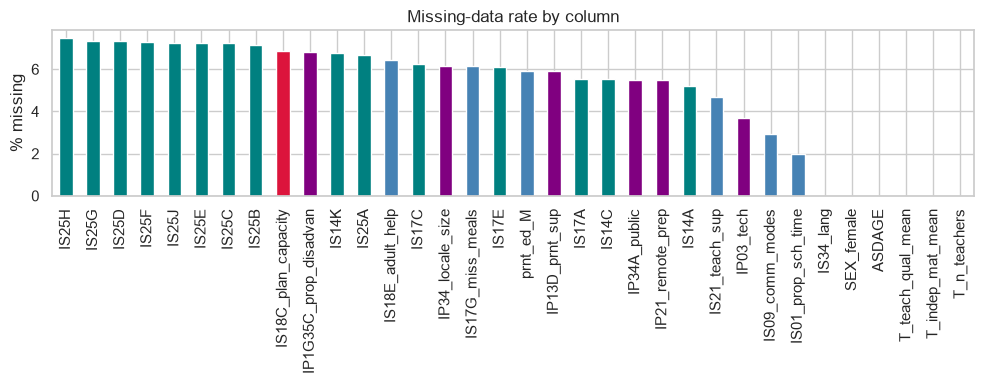

In [23]:
miss = (merged[ANALYSIS].isna().mean().mul(100).sort_values(ascending=False)
        .rename("% missing").to_frame())
miss["group"] = ["label" if c == LABEL else "difficulty" if c in DIFF else
                 "teacher" if c in TEACHER_X else "school" if c in SCHOOL_X else "student"
                 for c in miss.index]
display(miss.round(1))

row_miss = merged[ANALYSIS].isna().sum(axis=1)
print(f"Complete cases: {(row_miss == 0).sum():,} of {len(merged):,} "
      f"({(row_miss == 0).mean():.1%})")
print(f"Label missing: {merged[LABEL].isna().sum():,}")

fig, ax = plt.subplots(figsize=(10, 4))
miss["% missing"].plot.bar(ax=ax, color=miss["group"].map(
    {"label": "crimson", "student": "steelblue", "difficulty": "teal",
     "teacher": "darkorange", "school": "purple"}))
ax.set_ylabel("% missing"); ax.set_title("Missing-data rate by column"); plt.tight_layout(); plt.show()

In [24]:
# Is missingness related to the outcome? (MCAR vs MAR check for the biggest gaps)
top_missing = miss.index[(miss["% missing"] > 5) & (miss.index != LABEL)][:6]
for c in top_missing:
    tab = pd.crosstab(merged[c].isna(), merged[LABEL], normalize="index").round(3)
    tab.index = [f"{c} observed", f"{c} missing"][:len(tab)]
    display(tab)

IS18C_plan_capacity,1.0,2.0,3.0
IS25H observed,0.182,0.457,0.361
IS25H missing,0.317,0.415,0.268


IS18C_plan_capacity,1.0,2.0,3.0
IS25G observed,0.183,0.458,0.359
IS25G missing,0.291,0.367,0.342


IS18C_plan_capacity,1.0,2.0,3.0
IS25D observed,0.183,0.456,0.361
IS25D missing,0.312,0.429,0.260


IS18C_plan_capacity,1.0,2.0,3.0
IS25F observed,0.183,0.457,0.361
IS25F missing,0.300,0.425,0.275


IS18C_plan_capacity,1.0,2.0,3.0
IS25J observed,0.183,0.456,0.361
IS25J missing,0.306,0.444,0.250


IS18C_plan_capacity,1.0,2.0,3.0
IS25E observed,0.184,0.456,0.360
IS25E missing,0.276,0.434,0.289


### 4.3 Univariate descriptive statistics

In [25]:
desc = merged[ANALYSIS].describe().T
desc["skew"] = merged[ANALYSIS].skew(numeric_only=True)
display(desc.round(2))

lab = merged[LABEL].value_counts(dropna=False).sort_index()
lab_w = merged.groupby(LABEL)[WEIGHT].sum() / merged[WEIGHT].sum() if WEIGHT else None
print("Label distribution (unweighted):\n", (lab / lab.sum()).round(3))
if WEIGHT is not None:
    print("\nLabel distribution (weighted by TOTWGTS):\n", lab_w.round(3))

,count,mean,std,min,25%,50%,75%,max,skew
IS18C_plan_capacity,2783.0,2.17,0.72,1.00,2.00,2.00,3.00,3.00,-0.27
ASDAGE,2988.0,13.44,0.70,10.00,13.08,13.42,13.75,17.67,0.64
SEX_female,2988.0,0.52,0.50,0.00,0.00,1.00,1.00,1.00,-0.07
IS34_lang,2988.0,1.65,0.77,1.00,1.00,2.00,2.00,4.00,1.47
prnt_ed_M,2811.0,3.89,1.09,1.00,3.00,4.00,5.00,5.00,-0.76
IS17G_miss_meals,2804.0,1.76,1.01,1.00,1.00,1.00,2.00,4.00,1.08
IS01_prop_sch_time,2929.0,1.62,1.30,1.00,1.00,1.00,1.00,5.00,1.90
IS09_comm_modes,2901.0,2.18,1.15,0.00,1.00,2.00,3.00,4.00,0.04
IS21_teach_sup,2848.0,2.88,0.45,1.00,2.75,2.75,3.25,4.00,-0.54
IS18E_adult_help,2795.0,2.21,0.65,1.00,2.00,2.00,3.00,3.00,-0.24


Label distribution (unweighted):
 IS18C_plan_capacity
1.0    0.173
2.0    0.424
3.0    0.334
NaN    0.069
Name: count, dtype: float64

Label distribution (weighted by TOTWGTS):
 IS18C_plan_capacity
1.0    0.171
2.0    0.436
3.0    0.318
Name: TOTWGTS, dtype: float64


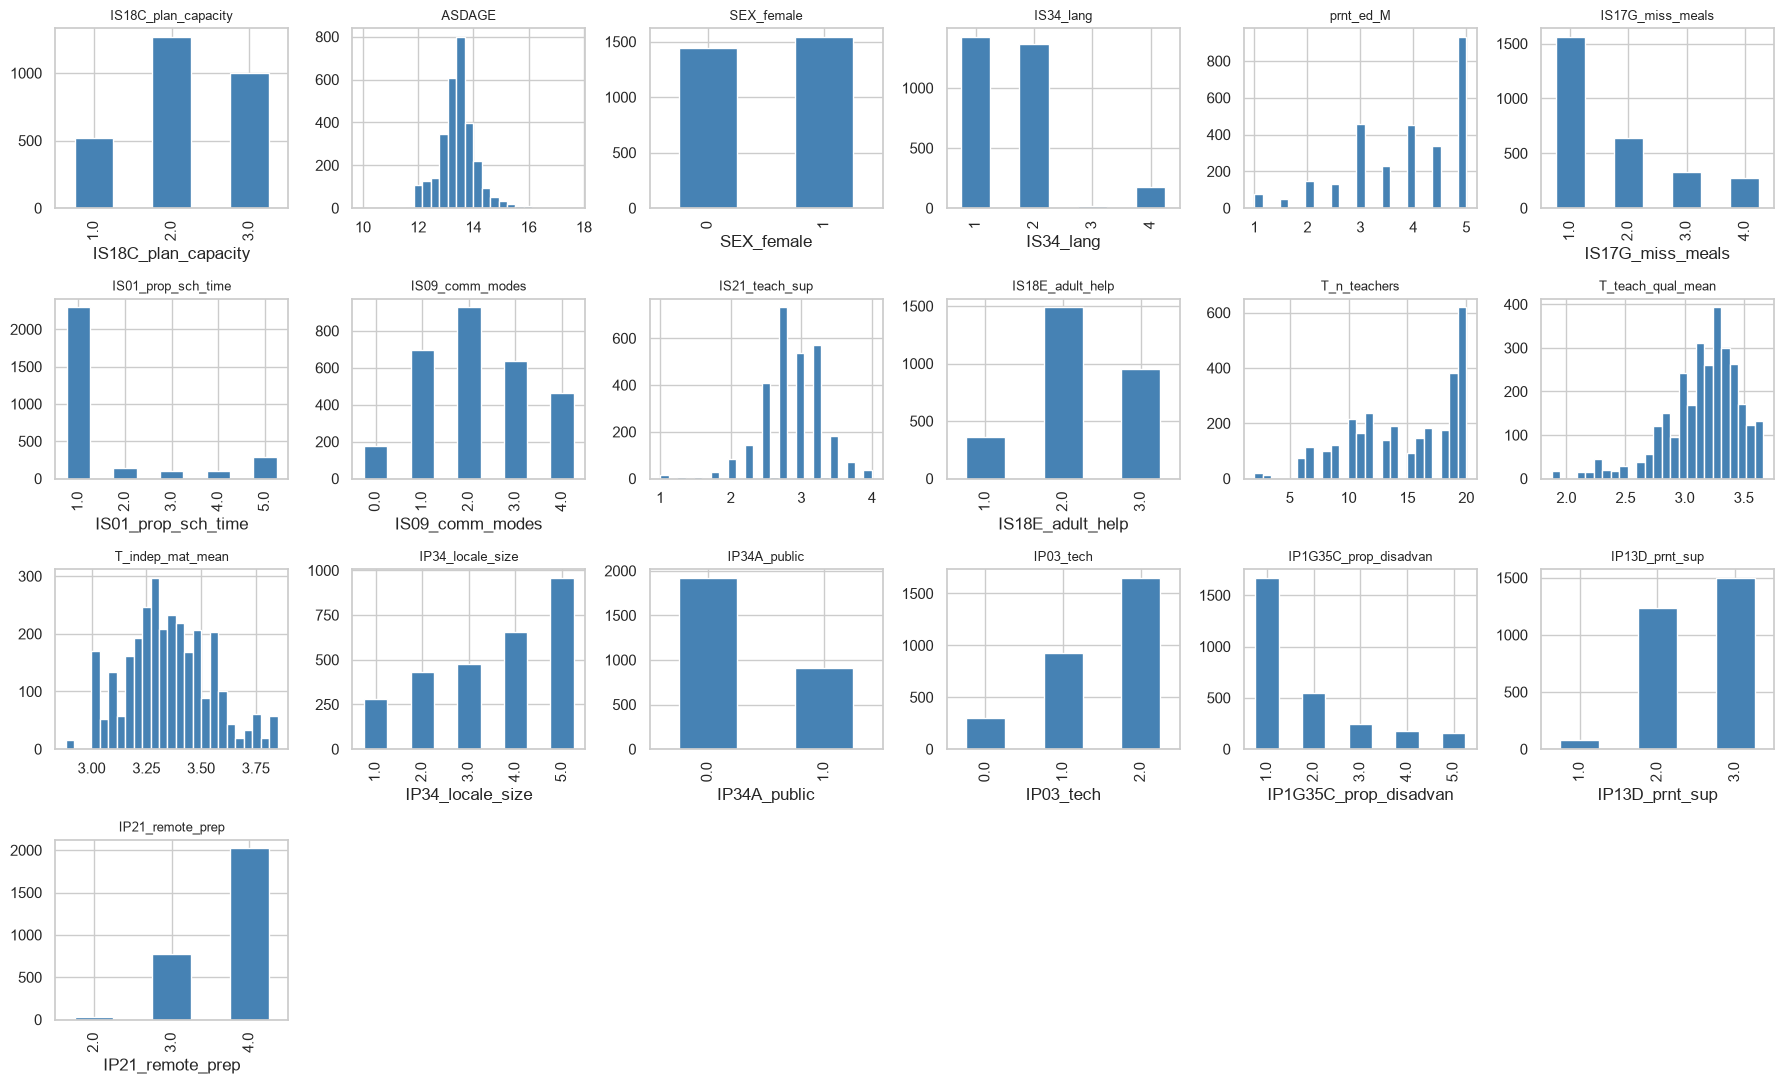

In [26]:
fig, axes = plt.subplots(4, 6, figsize=(18, 11))
for ax, c in zip(axes.ravel(), [LABEL] + STUDENT_X + TEACHER_X + SCHOOL_X):
    s = merged[c].dropna()
    if s.nunique() <= 7:
        s.value_counts().sort_index().plot.bar(ax=ax, color="steelblue")
    else:
        ax.hist(s, bins=25, color="steelblue")
    ax.set_title(c, fontsize=9)
for ax in axes.ravel()[len([LABEL] + STUDENT_X + TEACHER_X + SCHOOL_X):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

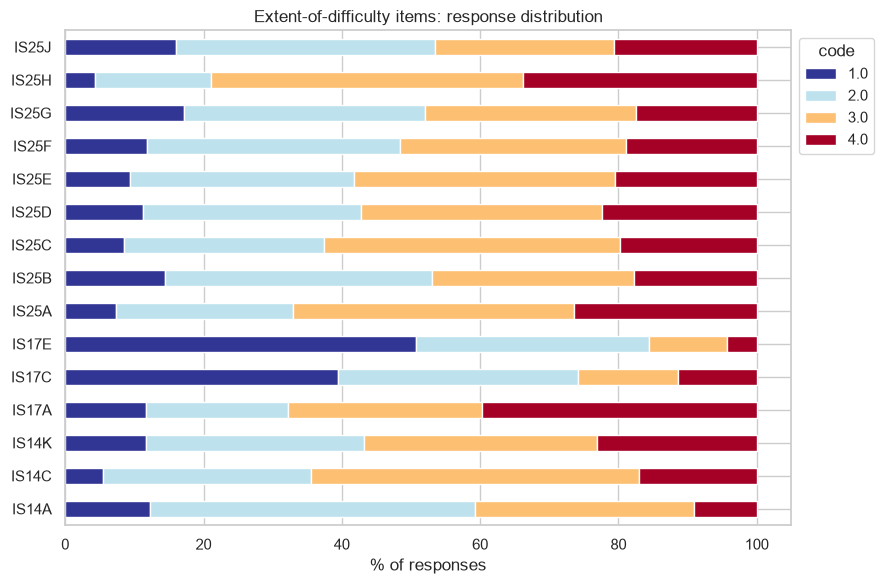

In [27]:
# Difficulty item set: response distribution (stacked %)
dist = (merged[DIFF].apply(lambda s: s.value_counts(normalize=True)).T.fillna(0) * 100)
dist.plot.barh(stacked=True, figsize=(9, 6), colormap="RdYlBu_r")
plt.xlabel("% of responses"); plt.title("Extent-of-difficulty items: response distribution")
plt.legend(title="code", bbox_to_anchor=(1, 1)); plt.tight_layout(); plt.show()

### 4.4 Bivariate correlations

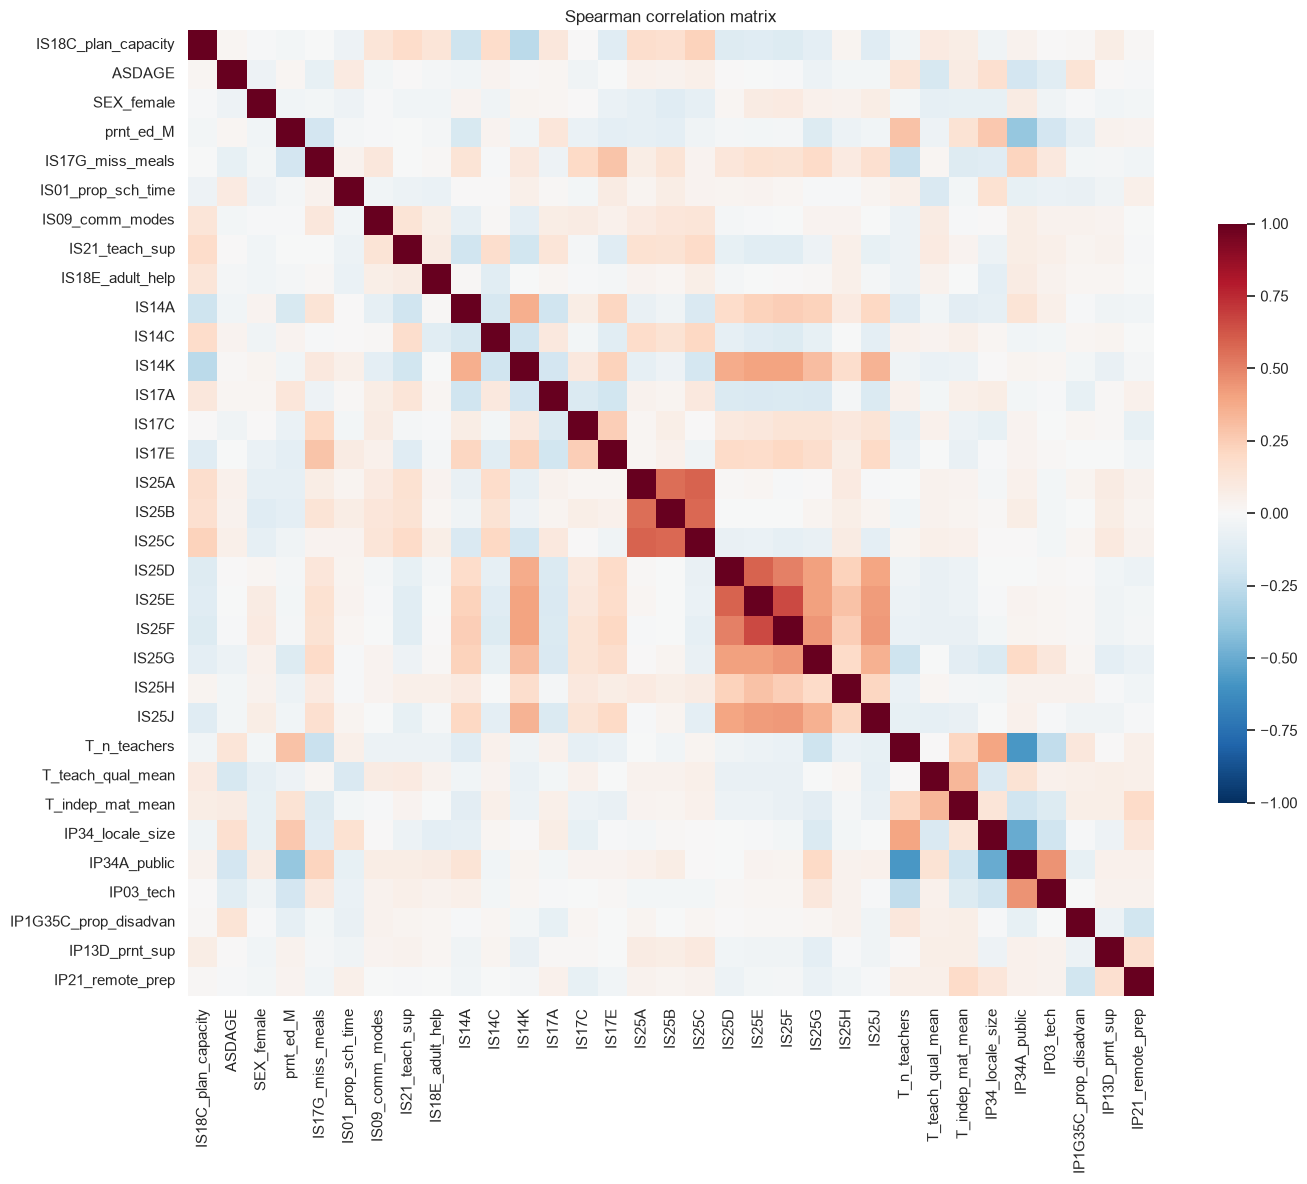

In [28]:
# Spearman: most columns are ordinal, so rank correlation is appropriate
num_cols = [c for c in ANALYSIS if c not in NOMINAL]
corr = merged[num_cols].corr(method="spearman")

plt.figure(figsize=(15, 12))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True,
            cbar_kws={"shrink": .6}, xticklabels=True, yticklabels=True)
plt.title("Spearman correlation matrix"); plt.tight_layout(); plt.show()

In [29]:
print("Correlation with the label (Spearman), strongest first:")
display(corr[LABEL].drop(LABEL).sort_values(key=abs, ascending=False).round(3).to_frame())

pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename("rho").reset_index())
pairs = pairs.reindex(pairs["rho"].abs().sort_values(ascending=False).index)
print("Strongest feature-feature pairs (|rho| >= 0.4):")
display(pairs[pairs["rho"].abs() >= .4].round(3).head(20))

Correlation with the label (Spearman), strongest first:


,IS18C_plan_capacity
IS14K,-0.271
IS25C,0.232
IS14A,-0.204
IS14C,0.184
IS21_teach_sup,0.183
IS25A,0.175
IS25B,0.159
IS25F,-0.140
IS25D,-0.131
IS09_comm_modes,0.131


Strongest feature-feature pairs (|rho| >= 0.4):


,level_0,level_1,rho
647,IS25E,IS25F,0.659
512,IS25A,IS25C,0.591
613,IS25D,IS25E,0.586
820,T_n_teachers,IP34A_public,-0.579
545,IS25B,IS25C,0.571
511,IS25A,IS25B,0.559
614,IS25D,IS25F,0.506
919,IP34_locale_size,IP34A_public,-0.501
953,IP34A_public,IP03_tech,0.446
681,IS25F,IS25G,0.442


In [30]:
# Language at home is nominal: compare the outcome distribution across languages (chi-square)
LANG = NOMINAL[0]
ct = pd.crosstab(merged[LANG], merged[LABEL])
chi2, p, dof, _ = stats.chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
display(pd.crosstab(merged[LANG], merged[LABEL], normalize="index").round(3))
print(f"Chi-square = {chi2:.1f}, df = {dof}, p = {p:.3g}, Cramer's V = {cramers_v:.3f}")

IS18C_plan_capacity,1.0,2.0,3.0
IS34_lang,,,
1,0.187,0.452,0.361
2,0.187,0.458,0.355
3,0.278,0.333,0.389
4,0.161,0.477,0.362


Chi-square = 2.4, df = 6, p = 0.884, Cramer's V = 0.021


### 4.5 Outlier observations (rows)

ASDAGE: 5 values outside [11, 17] -> [np.float64(10.0), np.float64(10.42), np.float64(17.25), np.float64(17.58), np.float64(17.67)]
Domain check done.

Mahalanobis outliers (p < .001): 58 rows (1.9%)
Students giving the same answer to all 15 difficulty items: 6


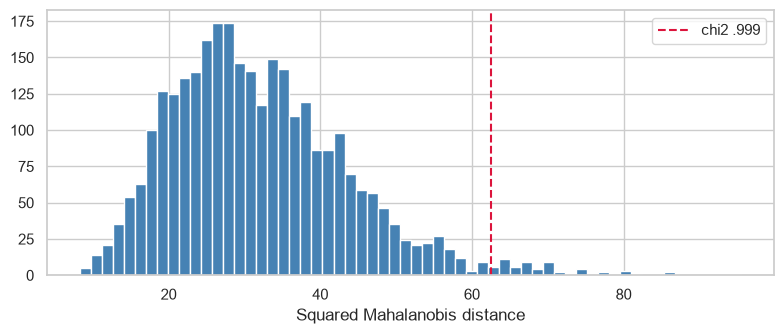

In [31]:
# (a) Domain checks: values outside the codebook range
RANGES = {col(merged, "ASDAGE"): (11, 17), col(merged, "IS09"): (0, 4), col(merged, "IS21"): (1, 4),
          col(merged, "IP03"): (0, 2), col(merged, "IS01"): (1, 5)}
RANGES.update({c: (1, 4) for c in DIFF})
for c, (lo, hi) in RANGES.items():
    bad = merged[c].notna() & ~merged[c].between(lo, hi)
    if bad.any():
        print(f"{c}: {bad.sum()} values outside [{lo}, {hi}] -> {sorted(merged.loc[bad, c].unique())[:10]}")
print("Domain check done.")

# (b) Multivariate outliers: Mahalanobis distance on the standardised numeric features
X_out = merged[num_cols].drop(columns=[LABEL])
X_out = X_out.fillna(X_out.median())                   # only for outlier screening
Z = StandardScaler().fit_transform(X_out)
cov_inv = np.linalg.pinv(np.cov(Z, rowvar=False))
d2 = np.einsum("ij,jk,ik->i", Z, cov_inv, Z)
cutoff = stats.chi2.ppf(0.999, df=Z.shape[1])
merged["mahal_d2"] = d2
merged["mv_outlier"] = d2 > cutoff
print(f"\nMahalanobis outliers (p < .001): {merged['mv_outlier'].sum():,} rows "
      f"({merged['mv_outlier'].mean():.1%})")

# (c) Response-pattern outliers: straight-lining the 15 difficulty items
straight = merged[DIFF].nunique(axis=1).eq(1) & merged[DIFF].notna().all(axis=1)
print(f"Students giving the same answer to all 15 difficulty items: {straight.sum():,}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(d2, bins=60, color="steelblue"); ax.axvline(cutoff, color="crimson", ls="--", label="chi2 .999")
ax.set_xlabel("Squared Mahalanobis distance"); ax.legend(); plt.tight_layout(); plt.show()

In [32]:
# What makes the outliers unusual? Compare their profile to everyone else
profile = merged.groupby("mv_outlier")[num_cols].mean().T
profile["diff_in_SD"] = (profile[True] - profile[False]) / merged[num_cols].std()
display(profile.sort_values("diff_in_SD", key=abs, ascending=False).head(10).round(2))

mv_outlier,False,True,diff_in_SD
IS01_prop_sch_time,1.60,2.47,0.67
IP21_remote_prep,3.71,3.43,-0.59
IS17A,2.97,2.36,-0.59
IS17G_miss_meals,1.75,2.25,0.50
IS25H,3.09,2.75,-0.42
IS17E,1.69,2.02,0.40
IP13D_prnt_sup,2.51,2.31,-0.36
SEX_female,0.52,0.34,-0.35
T_indep_mat_mean,3.35,3.29,-0.34
IS25D,2.69,2.38,-0.33


**Summary of the initial analysis**

* **Missing data.** Missingness is low for every column (at most **7.5%**). The highest rates are in the well-being items `IS25A-J` (7.1-7.5%), then the label (6.9%, 205 students). The teacher aggregates are complete, and the school-head columns are missing for whole schools (5-7%). **75.1% of rows (2,245) are complete cases.** Missingness is *not* random with respect to the outcome. Students who skipped the IS25 well-being block (167 skipped every item in it) report "Decreased" planning capacity far more often (≈30% vs 18%). The data are therefore at best MAR, and dropping these students would make the sample look better off than it is.
* **Univariate.** The label leans toward "Did not change" (42.4%), then "Increased" (33.4%), then "Decreased" (17.3%), with 6.9% missing. Weighting by `TOTWGTS` changes this very little (17.1 / 43.6 / 31.8%). `TOTWGTS` has a single value per school (1.4-116), so it reflects the school selection probability. Most students learned fully remotely (`IS01` median = 1, skew 1.9), most rarely missed meals (`IS17G`), and most attend schools with < 5% disadvantaged students (`IP1G35C`). These skewed columns carry little variance. Only 32% of students attend public schools. Mean age is 13.4.
* **Bivariate.** All correlations with the label are weak (|rho| <= .27). The strongest are **difficulty concentrating `IS14K` (−.27)**, **felt fit and healthy `IS25C` (+.23)**, **hard to understand schoolwork `IS14A` (−.20)**, **able to complete work without help `IS14C` (+.18)**, **teacher support `IS21` (+.18)** and **exercise/hobbies `IS25A/B` (+.18/+.16)**. Teacher and school variables are essentially uncorrelated with the label (|rho| < .10), and language at home is unrelated (chi² p = .88, Cramér's V = .02). Within the features, the **distress items `IS25D-J` correlate strongly with each other (up to .66)**, and so do the **activity items `IS25A-C` (.56-.59)**. This redundancy motivates Q6. At the school level, public schools have fewer responding teachers (rho = −.58), are in smaller localities (−.50) and provide more technology (+.45).
* **Outliers.** All Likert values are inside their codebook ranges, which bounded scales guarantee. **5 students have ages outside 11-17** (10.0, 10.4, 17.3, 17.6, 17.7), which is unusual for Grade 8 and worth checking, but plausible (grade repetition or early entry). The Mahalanobis screen flags **58 rows (1.9%)** with unusual *combinations* of answers. These students attended more lessons in school (`IS01`), missed meals more often, more often lacked a quiet space, are more often male, and their schools report lower remote-learning readiness. In other words, they are a coherent disadvantaged subgroup rather than data errors. **6 students** gave the same answer to all 15 difficulty items (possible careless responding). Outliers are flagged, not deleted.

---
## Q5. Should we impute missing values? Should we augment with new rows?

**Imputation: yes, for the features, carefully; no, for the label.**
* The amount of missing data is small (<= 7.5% per column, 75% complete cases), but listwise deletion across all columns would still lose a quarter of the students. More importantly, the missingness is **related to the outcome**: students who skipped the IS25 block report "Decreased" much more often. Deleting them biases the sample toward students who coped well, so the features are worth imputing (MAR, not MCAR).
* The right method depends on the column type:
  * Ordinal Likert items: impute with the mode, or better, with **multiple imputation / iterative imputation**, which uses the strong correlations inside the item set. For the difficulty scale specifically, *person-mean imputation* across a student's other items is common when only one or two items are missing.
  * Teacher/school aggregates that are missing for a whole school cannot be recovered from that school's other students. Mean-imputing them would invent school characteristics. A **missing-indicator** column plus a neutral fill keeps the information that "this school did not respond".
  * Rows with a missing **label** are dropped. Imputing the outcome would build our own assumptions into the target.
* Tree models in scikit-learn >= 1.3 handle `NaN` natively, so Q7 needs no imputation. In Q6 the difficulty items are used to compute factor scores for every student who answered at least 12 of the 15 items (2,760 students). For the logistic regression (Q8), complete cases on the reduced feature set keep **2,510 of 2,783 labelled students (90%)**, so the remaining loss is small.

**Augmentation (adding synthetic rows): not useful here.**
* REDS is a probability sample with sampling weights (`TOTWGTS`). Synthetic rows (SMOTE, bootstrapped copies) have no valid weight and would distort the population estimates and the standard errors, which are the whole point of a survey analysis.
* The sample is already reasonably large (2,783 labelled students), and the smallest class, "Decreased", still has 518 students (17%). If class imbalance hurts prediction, **class weights** (or sampling weights) give the same benefit without creating fake students.
* Students are clustered within schools, and synthetic rows would understate this clustering. Augmentation would only make sense for prediction-only goals with a very rare class, which is not the case here.

---
## Q6. Dimensionality reduction of the "extent of difficulty experienced" item set

In [33]:
items = merged[DIFF].copy()
display(items.describe().T.round(2))
display(items.corr(method="spearman").round(2).style.background_gradient(cmap="RdBu_r", vmin=-1, vmax=1))

,count,mean,std,min,25%,50%,75%,max
IS14A,2832.0,2.37,0.81,1.0,2.0,2.0,3.0,4.0
IS14C,2823.0,2.76,0.80,1.0,2.0,3.0,3.0,4.0
IS14K,2786.0,2.68,0.96,1.0,2.0,3.0,3.0,4.0
IS17A,2822.0,2.96,1.04,1.0,2.0,3.0,4.0,4.0
IS17C,2802.0,1.98,1.00,1.0,1.0,2.0,3.0,4.0
IS17E,2805.0,1.69,0.84,1.0,1.0,1.0,2.0,4.0
IS25A,2788.0,2.86,0.89,1.0,2.0,3.0,4.0,4.0
IS25B,2775.0,2.50,0.95,1.0,2.0,2.0,3.0,4.0
IS25C,2772.0,2.74,0.87,1.0,2.0,3.0,3.0,4.0
IS25D,2769.0,2.68,0.94,1.0,2.0,3.0,3.0,4.0


,IS14A,IS14C,IS14K,IS17A,IS17C,IS17E,IS25A,IS25B,IS25C,IS25D,IS25E,IS25F,IS25G,IS25H,IS25J
IS14A,1.000000,-0.170000,0.360000,-0.200000,0.080000,0.210000,-0.070000,-0.050000,-0.150000,0.190000,0.230000,0.240000,0.230000,0.090000,0.210000
IS14C,-0.170000,1.000000,-0.200000,0.110000,-0.030000,-0.120000,0.180000,0.150000,0.200000,-0.090000,-0.120000,-0.130000,-0.090000,-0.000000,-0.100000
IS14K,0.360000,-0.200000,1.000000,-0.190000,0.110000,0.230000,-0.090000,-0.050000,-0.180000,0.370000,0.400000,0.400000,0.310000,0.180000,0.350000
IS17A,-0.200000,0.110000,-0.190000,1.000000,-0.150000,-0.190000,0.040000,0.030000,0.110000,-0.140000,-0.150000,-0.140000,-0.150000,-0.020000,-0.150000
IS17C,0.080000,-0.030000,0.110000,-0.150000,1.000000,0.250000,0.020000,0.060000,0.010000,0.100000,0.110000,0.140000,0.140000,0.100000,0.140000
IS17E,0.210000,-0.120000,0.230000,-0.190000,0.250000,1.000000,0.020000,0.050000,-0.050000,0.190000,0.190000,0.200000,0.180000,0.070000,0.200000
IS25A,-0.070000,0.180000,-0.090000,0.040000,0.020000,0.020000,1.000000,0.560000,0.590000,0.010000,0.020000,-0.010000,0.000000,0.090000,-0.010000
IS25B,-0.050000,0.150000,-0.050000,0.030000,0.060000,0.050000,0.560000,1.000000,0.570000,-0.010000,-0.010000,-0.000000,0.020000,0.060000,0.030000
IS25C,-0.150000,0.200000,-0.180000,0.110000,0.010000,-0.050000,0.590000,0.570000,1.000000,-0.070000,-0.070000,-0.090000,-0.080000,0.080000,-0.100000
IS25D,0.190000,-0.090000,0.370000,-0.140000,0.100000,0.190000,0.010000,-0.010000,-0.070000,1.000000,0.590000,0.510000,0.410000,0.230000,0.390000


### 6(a) Is a transformation needed? **Yes.**
1. **Reverse-code the positively worded items** so that a higher score always means *more difficulty*. I check each item's direction empirically (table below) by correlating it with the clearly negative items. Five items run opposite to the difficulty items and are flipped (x -> 5 - x): `IS14C` (able to complete without help), `IS17A` (quiet space), `IS25A` (exercised more), `IS25B` (more hobbies), `IS25C` (felt fit and healthy). **`IS17E` is not reversed**, even though the codebook label "adequate materials" sounds positive. In the data it correlates **+.29** with the difficulty items and **−.12** with the label, and its mean is low (1.69, mostly "never"). It therefore behaves like a negatively worded item ("did *not* have adequate materials"), and flipping it would break its scale. This is worth confirming with the original REDS item wording. Without consistent directions, the loadings mix signs, and the reliability of a scale can even turn negative.
2. **Standardise (PCA on the correlation matrix).** All items use 1-4 codes, but sets 14/25 are agree-disagree and set 17 is a frequency scale, with different variances. Standardising stops items with higher variance from dominating.
3. **Missing values:** PCA/FA is fitted on the 2,561 students (85.7%) who answered all 15 items. Factor *scores* are then computed for every student who answered at least 12 items (2,760), with each gap filled by that item's median. The 167 students who skipped the whole IS25 block cannot be scored.
4. **Factor orientation:** the sign of a factor is arbitrary, so each factor is flipped if needed so that a higher score = more difficulty. This makes the odds ratios in Q8 read in the intended direction.
5. The items are ordinal. A polychoric-correlation factor analysis would be ideal. Pearson-based PCA/FA on 4-point items is the standard practical approximation and is good enough for exploration.

,rho_with_clear_difficulty,rho_with_label
IS14A,0.50,-0.20
IS14C,-0.18,0.18
IS14K,0.66,-0.27
IS17A,-0.22,0.11
IS17C,0.16,0.00
IS17E,0.29,-0.12
IS25A,-0.02,0.18
IS25B,-0.00,0.16
IS25C,-0.14,0.23
IS25D,0.72,-0.13


Rows with all 15 items: 2,561 of 2,988 (85.7%)
Eigenvalues: [3.84 2.26 1.23 0.98 0.9  0.83 0.82 0.68 0.66 0.65 0.56 0.49 0.42 0.38
 0.3 ]
Kaiser (eig > 1): 3 components | parallel analysis: 3 components


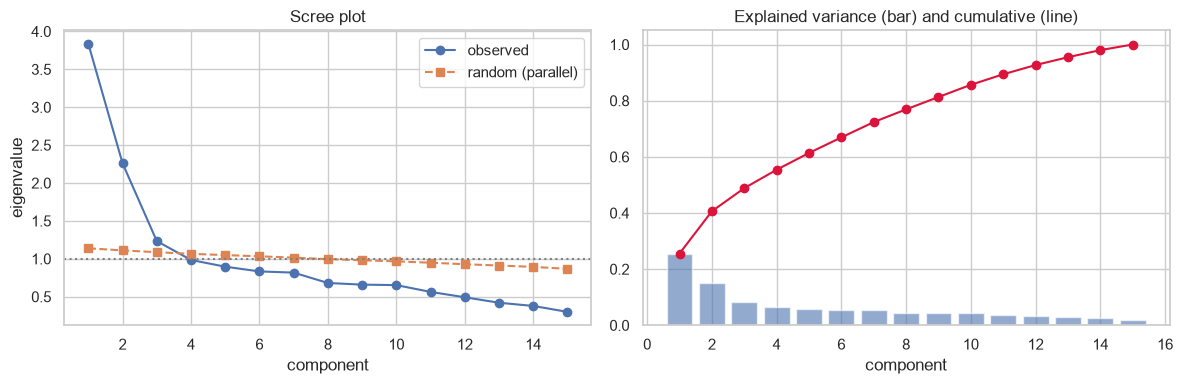

In [34]:
# Empirical check of each item's direction: correlate it with the clearly negative items
CLEAR_NEG = [col(merged, c) for c in ["IS14A", "IS14K", "IS25D", "IS25E", "IS25F", "IS25G", "IS25J"]]
direction = pd.DataFrame({
    "rho_with_clear_difficulty": items.corrwith(items[CLEAR_NEG].mean(axis=1), method="spearman"),
    "rho_with_label": items.corrwith(merged[LABEL], method="spearman")}).round(2)
display(direction)

# Positively worded items that run opposite to the difficulty items -> reverse (x -> 5 - x).
# IS17E is NOT reversed: in this data it correlates positively with the difficulty items
# (rho = +.29) and negatively with the label, so a high IS17E score already means more difficulty.
REVERSE = [col(merged, c) for c in ["IS14C", "IS17A", "IS25A", "IS25B", "IS25C"]]
items_t = items.copy()
items_t[REVERSE] = 5 - items_t[REVERSE]
items_t.columns = [c + ("_R" if c in REVERSE else "") for c in items.columns]

complete = items_t.dropna()
print(f"Rows with all 15 items: {len(complete):,} of {len(items_t):,} ({len(complete)/len(items_t):.1%})")

Zd = StandardScaler().fit_transform(complete)
pca = PCA(random_state=RANDOM_STATE).fit(Zd)
eig = pca.explained_variance_

# Parallel analysis: compare against eigenvalues from random data of the same size
rng = np.random.default_rng(RANDOM_STATE)
rand_eig = np.mean([PCA().fit(rng.standard_normal(Zd.shape)).explained_variance_ for _ in range(30)], axis=0)
n_keep_kaiser = int((eig > 1).sum())
n_keep_pa = int((eig > rand_eig).sum())
print("Eigenvalues:", eig.round(2))
print(f"Kaiser (eig > 1): {n_keep_kaiser} components | parallel analysis: {n_keep_pa} components")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
k = np.arange(1, len(eig) + 1)
axes[0].plot(k, eig, "o-", label="observed"); axes[0].plot(k, rand_eig, "s--", label="random (parallel)")
axes[0].axhline(1, color="grey", ls=":"); axes[0].set_xlabel("component"); axes[0].set_ylabel("eigenvalue")
axes[0].set_title("Scree plot"); axes[0].legend()
axes[1].bar(k, pca.explained_variance_ratio_, alpha=.6)
axes[1].plot(k, np.cumsum(pca.explained_variance_ratio_), "o-", color="crimson")
axes[1].set_title("Explained variance (bar) and cumulative (line)"); axes[1].set_xlabel("component")
plt.tight_layout(); plt.show()

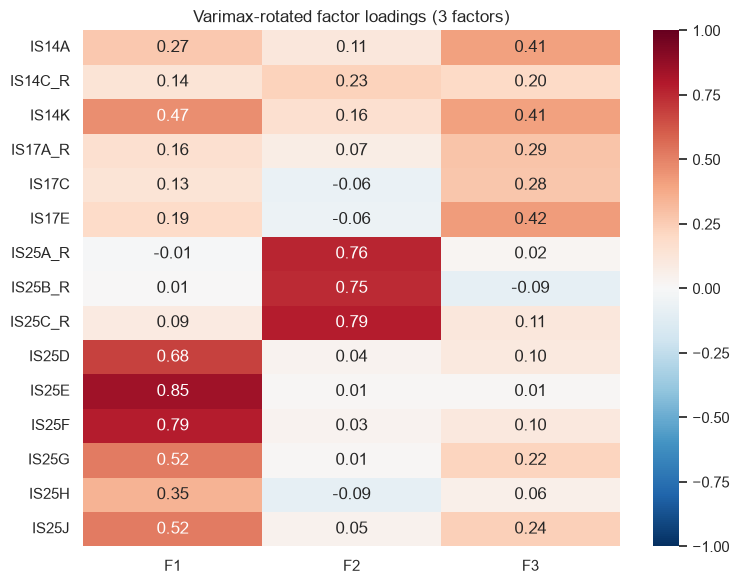

Main factor for each item (|loading| >= .30):
  F1: IS25E, IS25F, IS25D, IS25G, IS25J, IS14K, IS25H
  F2: IS25C_R, IS25A_R, IS25B_R
  F3: IS17E, IS14A, IS14K


In [35]:
N_COMP = max(n_keep_pa, 2)
fa = FactorAnalysis(n_components=N_COMP, rotation="varimax", random_state=RANDOM_STATE).fit(Zd)
loadings = pd.DataFrame(fa.components_.T, index=complete.columns,
                        columns=[f"F{i+1}" for i in range(N_COMP)])
# The sign of a factor is arbitrary: orient each one so that a higher score = more difficulty
SIGNS = np.sign(loadings.sum()).replace(0, 1).to_numpy()
loadings = loadings * SIGNS

plt.figure(figsize=(1.6 * N_COMP + 3, 6))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title(f"Varimax-rotated factor loadings ({N_COMP} factors)"); plt.tight_layout(); plt.show()

print("Main factor for each item (|loading| >= .30):")
for f in loadings.columns:
    top = loadings[f][loadings[f].abs() >= .30].sort_values(key=abs, ascending=False)
    print(f"  {f}: {', '.join(top.index)}")

In [36]:
# Internal consistency of each item cluster (Cronbach's alpha)
def cronbach_alpha(df):
    df = df.dropna(); k = df.shape[1]
    return k / (k - 1) * (1 - df.var(ddof=1).sum() / df.sum(axis=1).var(ddof=1))

salient = loadings.abs().max(axis=1) >= .30
assign = loadings[salient].abs().idxmax(axis=1)
print("Items with no loading >= .30:", loadings.index[~salient].tolist())
for f in loadings.columns:
    its = assign.index[assign == f].tolist()
    if len(its) >= 2:
        print(f"{f}: alpha = {cronbach_alpha(complete[its]):.2f}  ({len(its)} items: {its})")
acad = [c for c in complete.columns if c[:4] in ("IS14", "IS17")]
print(f"Theoretical academic/home subscale (all 6 IS14/IS17 items): alpha = {cronbach_alpha(complete[acad]):.2f}")

# Factor scores -> new engineered features. The model is fitted on complete rows only, but students
# who answered at least 12 of the 15 items are also scored, with each gap filled by that item's median.
MIN_ITEMS = 12
scorable = items_t[items_t.notna().sum(axis=1) >= MIN_ITEMS]
filled = scorable.fillna(complete.median())
scaler_d = StandardScaler().fit(complete)
scores = pd.DataFrame(fa.transform(scaler_d.transform(filled)) * SIGNS, index=scorable.index,
                      columns=[f"DIFF_F{i+1}" for i in range(N_COMP)])
# Name each factor after the item group that loads most strongly on it
def factor_name(f):
    top = loadings[f].idxmax()
    if top[:5] in ("IS25A", "IS25B", "IS25C"): return "DIFF_low_activity"
    if top[:4] == "IS25": return "DIFF_distress"
    return "DIFF_academic_home"
FNAMES = {f"DIFF_F{i+1}": factor_name(f) for i, f in enumerate(loadings.columns)}
scores = scores.rename(columns=FNAMES)
print("Factor names:", FNAMES)
print(f"Students with factor scores: {len(scores):,} (complete: {len(complete):,}; "
      f">= {MIN_ITEMS} items answered: {len(scorable):,})")
merged = merged.drop(columns=[c for c in merged if c.startswith("DIFF_")], errors="ignore").join(scores)
print("\nCorrelation of factor scores with the label (Spearman):")
print(merged[scores.columns.tolist() + [LABEL]].corr(method="spearman")[LABEL].drop(LABEL).round(3))

Items with no loading >= .30: ['IS14C_R', 'IS17A_R', 'IS17C']
F1: alpha = 0.81  (7 items: ['IS14K', 'IS25D', 'IS25E', 'IS25F', 'IS25G', 'IS25H', 'IS25J'])
F2: alpha = 0.81  (3 items: ['IS25A_R', 'IS25B_R', 'IS25C_R'])
F3: alpha = 0.34  (2 items: ['IS14A', 'IS17E'])
Theoretical academic/home subscale (all 6 IS14/IS17 items): alpha = 0.54
Factor names: {'DIFF_F1': 'DIFF_distress', 'DIFF_F2': 'DIFF_low_activity', 'DIFF_F3': 'DIFF_academic_home'}
Students with factor scores: 2,760 (complete: 2,561; >= 12 items answered: 2,760)

Correlation of factor scores with the label (Spearman):
DIFF_distress        -0.145
DIFF_low_activity    -0.233
DIFF_academic_home   -0.214
Name: IS18C_plan_capacity, dtype: float64


### 6(b) Noteworthy results
* **Three dimensions.** The first three eigenvalues (3.84, 2.26, 1.23) are the only ones above 1, and parallel analysis agrees (3 factors). Together they explain **48.8%** of the variance in the 15 items. The "difficulty" item set is therefore not one scale, but it does reduce to a few dimensions.
* **Factors (varimax-rotated, oriented so that higher = more difficulty):**
  1. **Emotional distress (`DIFF_distress`)**: `IS25E` upset (.85), `IS25F` angry (.79), `IS25D` lonely (.68), `IS25G` avoiding friends, `IS25J` poor sleep (.52), plus `IS14K` difficulty concentrating (.47). **α = .81.** This is the strongest and most coherent factor.
  2. **Low physical activity / fitness (`DIFF_low_activity`)**: reversed `IS25A` exercise (.76), `IS25B` hobbies (.75), `IS25C` fit and healthy (.79). **α = .81.** These items are part of the "well-being" block, but they form a separate dimension from distress.
  3. **Academic / home-learning difficulty (`DIFF_academic_home`)**: `IS14A` hard to understand (.41), `IS14K` (.41), `IS17E` (.42), with weaker loadings from `IS17A` quiet space and `IS17C` sibling care (~.28). This factor is **weak**. Its salient items have α = .34, and all six IS14/IS17 items together only α = .54. These items measure different circumstances (understanding the material, the physical space, caring duties) rather than one trait.
* `IS14C_R`, `IS17A_R` and `IS17C` do not load >= .30 on any factor, and `IS25H` ("more worried") loads only weakly on distress (.35). They contribute little shared variance.
* **Link to the outcome:** all three factor scores correlate negatively with the planning-capacity label: low activity −.23, academic/home −.21, distress −.15. The 15 items are replaced by 3 nearly uncorrelated features (VIF < 1.2 in Q8), which removes the multicollinearity among the IS25 items.

---
## Q7. Feature selection with a decision tree

### 7(a) Is a transformation needed? **Only a little.**
* **No scaling or normalisation.** A tree splits on thresholds, so any monotonic transformation (standardising, log) gives the same splits. Ordinal Likert codes can be used as they are.
* **Nominal columns must be one-hot encoded.** `IS34_lang` (1 = Arabic, 2 = English, 3 = Persian, 4 = Urdu) has no order. Used as a number, the tree could only split "Arabic+English vs Persian+Urdu"-style groups defined by the arbitrary coding. Dummy columns let it isolate any single language.
* **Remove the identifiers and non-features:** `IDSTUD`, `IDSCHOOL` (a tree would memorise school IDs) and `TOTWGTS`. The weight is passed as `sample_weight` so the tree reflects the population, not used as a predictor.
* **Missing values:** scikit-learn >= 1.3 trees learn which branch missing values should go to, so no imputation is needed. Only rows with a missing label are dropped.
* Reverse-coding the difficulty items does not matter for the tree. I use the raw items here so the selection runs at the item level, which lets us compare items directly with the Q6 factors.

In [37]:
FEATURES_7 = STUDENT_X + DIFF + TEACHER_X + SCHOOL_X
d7 = merged.dropna(subset=[LABEL]).copy()
X7 = pd.get_dummies(d7[FEATURES_7], columns=NOMINAL, prefix="lang", dummy_na=False, dtype=float)
y7 = d7[LABEL].astype(int)
w7 = d7[WEIGHT].to_numpy() if WEIGHT else None
print("X:", X7.shape, "| classes:", y7.value_counts().sort_index().to_dict())

X_tr, X_te, y_tr, y_te, w_tr, w_te = train_test_split(
    X7, y7, w7 if w7 is not None else np.ones(len(y7)), test_size=.25,
    stratify=y7, random_state=RANDOM_STATE)

cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
grid = GridSearchCV(
    DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    {"max_depth": [3, 4, 5, 6, 8], "min_samples_leaf": [20, 50, 100], "ccp_alpha": [0, 1e-4, 1e-3]},
    scoring="balanced_accuracy", cv=cv, n_jobs=-1)
grid.fit(X_tr, y_tr, sample_weight=w_tr)
tree = grid.best_estimator_
print("Best params:", grid.best_params_, f"| CV balanced acc = {grid.best_score_:.3f}")
print(f"Test balanced accuracy = {balanced_accuracy_score(y_te, tree.predict(X_te)):.3f} "
      f"(chance = {1/y7.nunique():.3f})")

X: (2783, 36) | classes: {1: 518, 2: 1268, 3: 997}
Best params: {'ccp_alpha': 0, 'max_depth': 4, 'min_samples_leaf': 20} | CV balanced acc = 0.491
Test balanced accuracy = 0.470 (chance = 0.333)


,gini_importance,perm_importance,perm_sd
IS14K,0.3751,0.0464,0.0095
IS18E_adult_help,0.1594,0.0285,0.0106
IS14C,0.1585,0.0308,0.0114
IS25C,0.1212,0.0437,0.0117
IS25A,0.0551,0.0095,0.0035
T_teach_qual_mean,0.0403,0.0000,0.0000
IS14A,0.0355,0.0032,0.0039
IS21_teach_sup,0.0210,0.0000,0.0000
ASDAGE,0.0170,0.0045,0.0022
IS09_comm_modes,0.0169,0.0000,0.0000


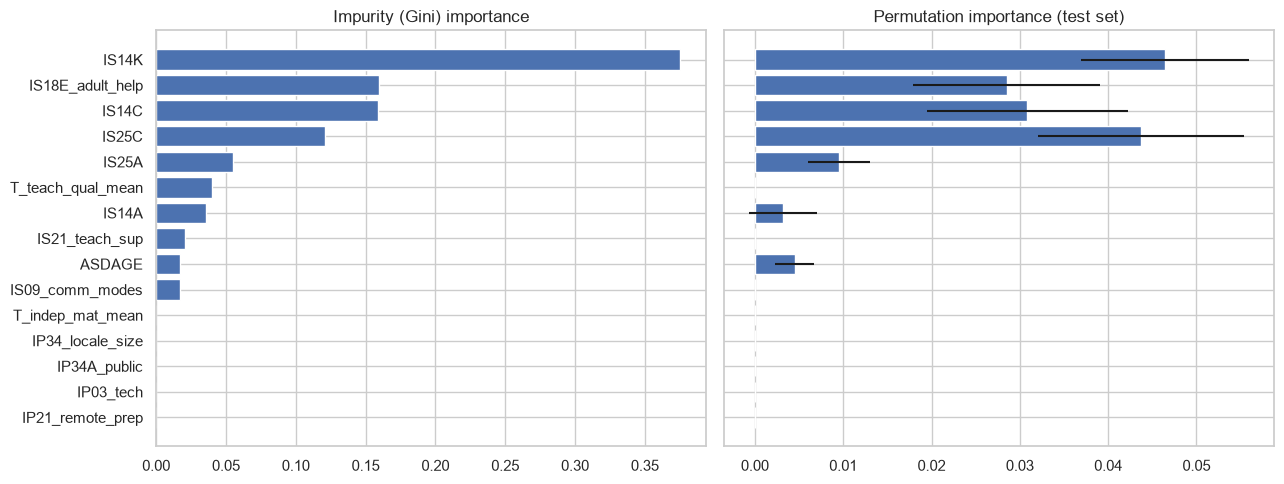

10 of 36 features used by the tree; selected (gini > .01 and positive permutation importance): ['IS14K', 'IS18E_adult_help', 'IS14C', 'IS25C', 'IS25A', 'IS14A', 'ASDAGE']


In [38]:
imp = pd.DataFrame({"gini_importance": tree.feature_importances_}, index=X7.columns)
perm = permutation_importance(tree, X_te, y_te, scoring="balanced_accuracy",
                              n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
imp["perm_importance"] = perm.importances_mean
imp["perm_sd"] = perm.importances_std
imp = imp.sort_values("gini_importance", ascending=False)
display(imp.head(15).round(4))

top = imp.head(15)
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
axes[0].barh(top.index[::-1], top["gini_importance"][::-1]); axes[0].set_title("Impurity (Gini) importance")
axes[1].barh(top.index[::-1], top["perm_importance"][::-1], xerr=top["perm_sd"][::-1])
axes[1].set_title("Permutation importance (test set)"); plt.tight_layout(); plt.show()

SELECTED = imp.index[(imp["gini_importance"] > 0.01) & (imp["perm_importance"] > 0)].tolist()
print(f"{(imp['gini_importance'] > 0).sum()} of {len(imp)} features used by the tree; "
      f"selected (gini > .01 and positive permutation importance): {SELECTED}")

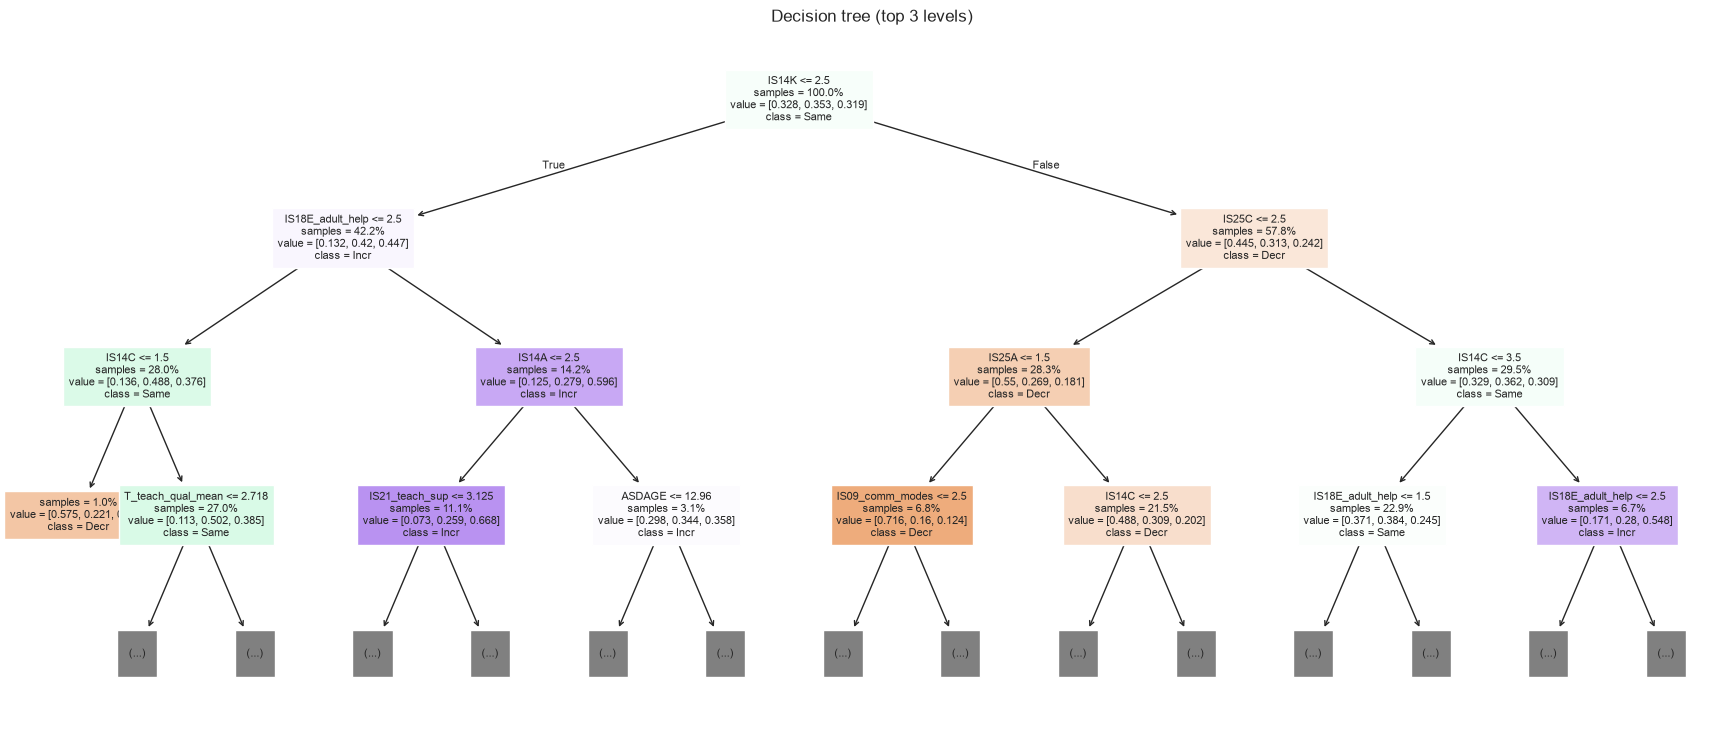

In [39]:
plt.figure(figsize=(22, 9))
plot_tree(tree, feature_names=X7.columns, class_names=["Decr", "Same", "Incr"], filled=True,
          max_depth=3, fontsize=8, impurity=False, proportion=True)
plt.title("Decision tree (top 3 levels)"); plt.show()

In [40]:
# Stability check: does the ranking hold across bootstrap resamples?
ranks = []
for b in range(25):
    idx = np.random.default_rng(b).integers(0, len(X_tr), len(X_tr))
    t = DecisionTreeClassifier(**{k: v for k, v in tree.get_params().items()}).fit(
        X_tr.iloc[idx], y_tr.iloc[idx], sample_weight=w_tr[idx])
    ranks.append(pd.Series(t.feature_importances_, index=X7.columns))
stab = pd.concat(ranks, axis=1)
stab_summary = pd.DataFrame({"mean_imp": stab.mean(axis=1),
                             "pct_in_top10": stab.rank(ascending=False).le(10).mean(axis=1) * 100})
display(stab_summary.sort_values("mean_imp", ascending=False).head(12).round(3))

,mean_imp,pct_in_top10
IS14K,0.368,100.0
IS14C,0.099,88.0
IS18E_adult_help,0.097,84.0
IS25A,0.065,56.0
IS25C,0.053,56.0
T_teach_qual_mean,0.048,68.0
IS14A,0.042,64.0
T_indep_mat_mean,0.029,44.0
IS25B,0.026,32.0
IS25D,0.018,32.0


### 7(b) Noteworthy results
* The tuned tree is shallow (**max_depth = 4, min_samples_leaf = 20**). Cross-validated balanced accuracy is **.49** and test balanced accuracy is **.47**, compared with .33 for chance. The label is predictable from these features, but only partly.
* The tree uses only **10 of 36 features**, and five of them carry almost all the importance:
  1. **`IS14K` difficulty concentrating**: Gini .38, the first split, and in the top 10 in **100%** of bootstrap resamples.
  2. **`IS18E_adult_help`** (change in adult help at home): .16, top 10 in 84% of resamples.
  3. **`IS14C`** able to complete schoolwork without help: .16, 88%.
  4. **`IS25C`** felt fit and healthy: .12. It has the second-highest *permutation* importance (.044).
  5. **`IS25A`** exercised more: .06.
* Selected features (Gini > .01 **and** positive permutation importance): `IS14K`, `IS18E_adult_help`, `IS14C`, `IS25C`, `IS25A`, `IS14A`, `ASDAGE`.
* **Teacher and school variables add almost nothing.** `T_teach_qual_mean` and `IS21_teach_sup` get some Gini importance (.04 and .02) but **zero permutation importance**: the tree splits on them, yet shuffling them does not hurt test performance. This is the bias of impurity importance toward many-valued features (the teacher means have ~88 distinct values). The school-head variables and language are never used.
* In substance, the outcome is driven by the student's **own** experience, namely the ability to concentrate and work independently, adult support at home, and physical well-being, rather than by school-level resources. This matches the bivariate correlations in Q4.
* Caveat: a single tree is unstable. Beyond the top 3, the ranking changes between resamples (for example `IS25A`/`IS25C` reach the top 10 in only 56% of resamples). A random forest would give a more stable ranking.

---
## Q8. Multinomial logistic regression: predict `IS18C_plan_capacity`

### 8(a) Feature rationale
I combine the **tree results (Q7)** with **theory**, and I prefer a short model that can be interpreted:
* **Q6 difficulty factors** (`DIFF_distress`, `DIFF_low_activity`, `DIFF_academic_home`) replace the 15 correlated items. They cover the item-level signals the tree found (`IS14K`, `IS14A`, `IS25A/C`) with little multicollinearity.
* **`IS21_teach_sup`** (teacher supportiveness) and **`IS09_comm_modes`** (how many ways the student communicated with teachers): structure and feedback from teachers should help students plan.
* **`IS18E_adult_help`**: the 2nd most important tree feature. More help from an adult at home is a direct support for organising schoolwork.
* **`IS01_prop_sch_time`**: more time in school during the disruption means more external structure.
* **Background controls:** `SEX_female`, `ASDAGE`, `prnt_ed_M` (socio-economic status) and language at home (`IS34_lang`, dummies).
* **One teacher aggregate (`T_indep_mat_mean`)** and **school `IP03_tech`** (devices/internet provided), to test whether school-level resources add anything beyond the student's own reports.
* Any further features selected in Q7 are added automatically by the code below.

### 8(b) Is a transformation needed? **Yes.**
1. **One-hot encode the nominal `IS34_lang`**, with Arabic as the reference category. A single numeric code would force an order and equal spacing that do not exist. Only **21 students speak Persian**, too few for a reliable estimate (its CI was 0.4-7.4), so Persian and Urdu are combined into one "Persian/Urdu" category (198 students).
2. **Standardise the continuous and ordinal predictors (z-scores).** Logistic regression does not need this to fit, but it puts the odds ratios on a common "per 1 SD" scale so effects can be compared. It also helps the solver converge and makes the regularised scikit-learn model fair across features. Binary indicators (`SEX_female`, language dummies) stay as 0/1, so their odds ratios are female-vs-male and so on.
3. **Treat the label as categorical**, with **"Did not change" (2) as the reference**. The model then estimates two contrasts: the odds of *Decreased vs No change* and of *Increased vs No change*.
4. **Missing values:** use complete cases on this reduced feature set (the drop is reported). Using factor scores instead of 15 items is what keeps enough rows.
5. **Multicollinearity check with VIF** after transformation. The Q6 factors were built partly to keep VIF low.

In [41]:
FEATS_8 = ([c for c in merged.columns if c.startswith("DIFF_")] +
           [col(merged, c) for c in ["IS21", "IS09", "IS18E", "IS01", "SEX", "ASDAGE", "prnt_ed", "IP03"]] +
           ["T_indep_mat_mean"])
# add any other tree-selected base features not already included (skip items represented by the factors)
for f in SELECTED:
    base = f if f in merged.columns else None
    if base and base not in FEATS_8 and base not in DIFF and base != LANG:
        FEATS_8.append(base)

d8 = merged[[LABEL, LANG] + FEATS_8 + ([WEIGHT] if WEIGHT else [])].dropna()
print(f"Complete cases for Q8: {len(d8):,} of {merged[LABEL].notna().sum():,} labelled students")

BINARY = [c for c in FEATS_8 if set(d8[c].unique()) <= {0, 1}]
CONT = [c for c in FEATS_8 if c not in BINARY]
X8 = d8[FEATS_8].copy().astype(float)
X8[CONT] = (X8[CONT] - X8[CONT].mean()) / X8[CONT].std()
# Persian (n = 21) is too small for its own dummy -> combine Persian + Urdu into "other"
lang8 = d8[LANG].astype(int).map({1: "arabic", 2: "english", 3: "persian_urdu", 4: "persian_urdu"})
lang_d = pd.get_dummies(lang8, prefix="lang", dtype=float).drop(columns="lang_arabic")  # Arabic = ref
X8 = pd.concat([X8, lang_d], axis=1)
y8 = d8[LABEL].astype(int)

from statsmodels.stats.outliers_influence import variance_inflation_factor
Xv = sm.add_constant(X8)
vif = pd.Series([variance_inflation_factor(Xv.values, i) for i in range(1, Xv.shape[1])], index=X8.columns)
print("Max VIF:", round(vif.max(), 2)); display(vif.sort_values(ascending=False).round(2).to_frame("VIF").head(8))

Complete cases for Q8: 2,510 of 2,783 labelled students
Max VIF: 1.7


,VIF
lang_english,1.70
IP03_tech,1.26
lang_persian_urdu,1.25
prnt_ed_M,1.21
T_indep_mat_mean,1.15
DIFF_academic_home,1.12
IS21_teach_sup,1.10
DIFF_low_activity,1.09


In [42]:
# Recode so that 'Did not change' (2) is the reference outcome (statsmodels uses the lowest code as base)
y8_ref = y8.map({2: 0, 1: 1, 3: 2})        # 0 = No change (ref), 1 = Decreased, 2 = Increased
mnl = sm.MNLogit(y8_ref, sm.add_constant(X8)).fit(method="newton", maxiter=200, disp=False)
print(mnl.summary(yname_list=["Decreased vs NoChange", "Increased vs NoChange"]))
print(f"\nMcFadden pseudo-R2 = {mnl.prsquared:.3f} | LLR p-value = {mnl.llr_pvalue:.3g}")

                           MNLogit Regression Results                          
Dep. Variable:     IS18C_plan_capacity   No. Observations:                 2510
Model:                         MNLogit   Df Residuals:                     2480
Method:                            MLE   Df Model:                           28
Date:                 Mon, 23 Nov 2026   Pseudo R-squ.:                 0.09754
Time:                         01:18:48   Log-Likelihood:                -2343.4
converged:                        True   LL-Null:                       -2596.7
Covariance Type:             nonrobust   LLR p-value:                 3.005e-89
Decreased vs NoChange       coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                    -1.2757      0.124    -10.266      0.000      -1.519      -1.032
DIFF_distress             0.4716      0.064      7.357      0.000       0.346       0.597


,feature,contrast,OR,CI_low,CI_high,p,sig
0,DIFF_distress,Decreased vs NoChange,1.603,1.413,1.817,0.000,***
1,DIFF_low_activity,Decreased vs NoChange,1.790,1.583,2.024,0.000,***
2,DIFF_academic_home,Decreased vs NoChange,1.743,1.533,1.981,0.000,***
3,IS21_teach_sup,Decreased vs NoChange,0.953,0.847,1.072,0.420,
4,IS09_comm_modes,Decreased vs NoChange,0.863,0.766,0.973,0.016,*
5,IS18E_adult_help,Decreased vs NoChange,1.014,0.903,1.137,0.819,
6,IS01_prop_sch_time,Decreased vs NoChange,0.973,0.866,1.093,0.646,
7,SEX_female,Decreased vs NoChange,0.779,0.612,0.991,0.042,*
8,ASDAGE,Decreased vs NoChange,1.085,0.965,1.221,0.172,
9,prnt_ed_M,Decreased vs NoChange,1.028,0.903,1.171,0.676,


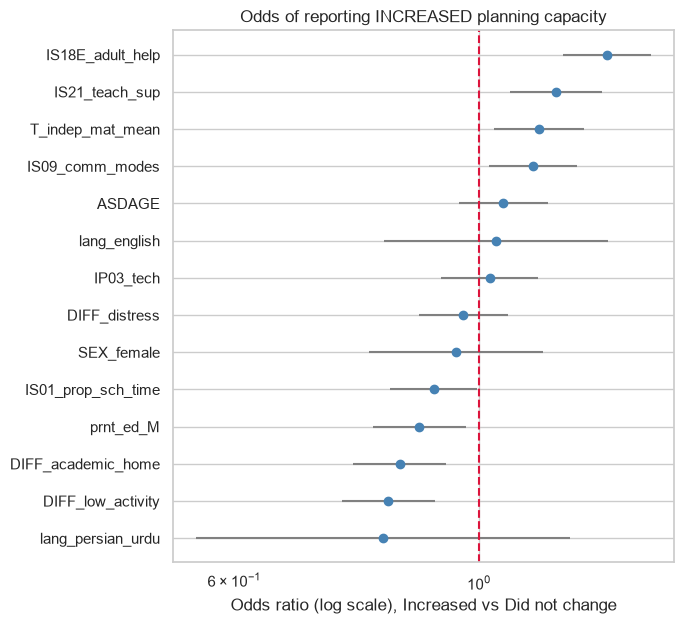

In [43]:
# Odds ratios (relative risk ratios) with 95% CIs
ci = mnl.conf_int()
rows = []
for j, name in enumerate(["Decreased vs NoChange", "Increased vs NoChange"]):
    p = mnl.params.iloc[:, j]; pv = mnl.pvalues.iloc[:, j]
    c = ci.xs(str(j + 1), level=0) if isinstance(ci.index, pd.MultiIndex) else ci
    rows.append(pd.DataFrame({"contrast": name, "OR": np.exp(p), "CI_low": np.exp(c.iloc[:, 0].values),
                              "CI_high": np.exp(c.iloc[:, 1].values), "p": pv}))
or_tab = pd.concat(rows).drop(index="const").rename_axis("feature").reset_index()
or_tab["sig"] = np.where(or_tab["p"] < .001, "***", np.where(or_tab["p"] < .01, "**",
                np.where(or_tab["p"] < .05, "*", "")))
display(or_tab.round(3))

inc = or_tab[or_tab["contrast"].str.startswith("Increased")].set_index("feature").sort_values("OR")
fig, ax = plt.subplots(figsize=(7, 0.35 * len(inc) + 1.5))
ax.errorbar(inc["OR"], inc.index, xerr=[inc["OR"] - inc["CI_low"], inc["CI_high"] - inc["OR"]],
            fmt="o", color="steelblue", ecolor="grey")
ax.axvline(1, color="crimson", ls="--"); ax.set_xscale("log")
ax.set_xlabel("Odds ratio (log scale), Increased vs Did not change")
ax.set_title("Odds of reporting INCREASED planning capacity"); plt.tight_layout(); plt.show()

In [44]:
# Survey-weighted refit (point estimates) as a sensitivity check
if WEIGHT:
    from sklearn.linear_model import LogisticRegression
    lr_w = LogisticRegression(C=1e6, max_iter=2000).fit(X8, y8_ref, sample_weight=d8[WEIGHT])
    lr_u = LogisticRegression(C=1e6, max_iter=2000).fit(X8, y8_ref)
    # sklearn's multinomial coefs are relative to a softmax; express vs class 0 for comparability
    def vs_ref(m): return pd.DataFrame((m.coef_[1:] - m.coef_[0]).T, index=X8.columns,
                                       columns=["Decr_vs_NC", "Incr_vs_NC"])
    cmp_ = pd.concat({"unweighted": np.exp(vs_ref(lr_u)), "weighted": np.exp(vs_ref(lr_w))}, axis=1)
    display(cmp_.round(3))

unweighted              weighted           
                   Decr_vs_NC Incr_vs_NC Decr_vs_NC Incr_vs_NC
DIFF_distress           1.602      0.968      1.680      1.010
DIFF_low_activity       1.789      0.828      1.811      0.839
DIFF_academic_home      1.743      0.847      1.790      0.859
IS21_teach_sup          0.953      1.175      0.954      1.155
IS09_comm_modes         0.863      1.119      0.848      1.111
IS18E_adult_help        1.014      1.307      1.061      1.335
IS01_prop_sch_time      0.973      0.909      0.951      0.886
SEX_female              0.780      0.952      0.799      1.013
ASDAGE                  1.086      1.052      1.052      1.067
prnt_ed_M               1.028      0.883      1.029      0.886
IP03_tech               1.078      1.023      1.030      0.992
T_indep_mat_mean        0.945      1.133      1.047      1.234
lang_english            1.233      1.036      1.184      0.870
lang_persian_urdu       1.071      0.817      1.012      0.770

5-fold CV accuracy          = 0.504 (majority baseline = 0.453)
5-fold CV balanced accuracy = 0.516 +/- 0.013 (chance = .333)
              precision    recall  f1-score   support

   Decreased       0.41      0.71      0.52       112
   No change       0.56      0.30      0.39       284
   Increased       0.48      0.58      0.52       232

    accuracy                           0.47       628
   macro avg       0.48      0.53      0.48       628
weighted avg       0.50      0.47      0.46       628



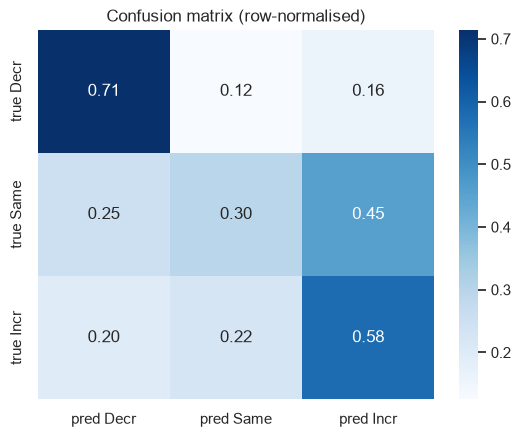

In [45]:
# Predictive performance (cross-validated), compared with the majority-class baseline
lr = LogisticRegression(max_iter=2000, class_weight="balanced")
cv_bal = cross_val_score(lr, X8, y8, cv=cv, scoring="balanced_accuracy")
cv_acc = cross_val_score(LogisticRegression(max_iter=2000), X8, y8, cv=cv, scoring="accuracy")
print(f"5-fold CV accuracy          = {cv_acc.mean():.3f} (majority baseline = {y8.value_counts(normalize=True).max():.3f})")
print(f"5-fold CV balanced accuracy = {cv_bal.mean():.3f} +/- {cv_bal.std():.3f} (chance = .333)")

Xa, Xb, ya, yb = train_test_split(X8, y8, test_size=.25, stratify=y8, random_state=RANDOM_STATE)
lr.fit(Xa, ya); pred = lr.predict(Xb)
print(classification_report(yb, pred, target_names=["Decreased", "No change", "Increased"]))
cm = pd.DataFrame(confusion_matrix(yb, pred, normalize="true"),
                  index=["true Decr", "true Same", "true Incr"], columns=["pred Decr", "pred Same", "pred Incr"])
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues"); plt.title("Confusion matrix (row-normalised)"); plt.show()

,P(No change),P(Decreased),P(Increased),odds_Increased_vs_rest,IS18C_plan_capacity
1,0.446,0.256,0.299,0.426,3.0
3,0.370,0.100,0.530,1.128,2.0
4,0.435,0.111,0.454,0.832,2.0
5,0.430,0.094,0.475,0.906,3.0
7,0.393,0.188,0.419,0.723,2.0
9,0.385,0.179,0.436,0.774,3.0
11,0.345,0.405,0.249,0.332,3.0
13,0.292,0.601,0.108,0.121,1.0
14,0.386,0.280,0.335,0.503,1.0
15,0.596,0.100,0.304,0.438,2.0


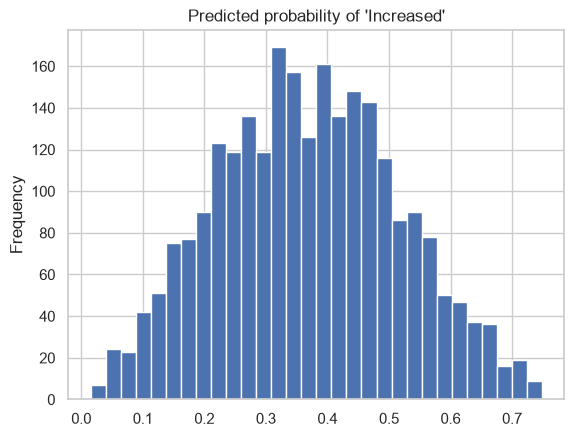

In [46]:
# Predicted probabilities for individual students: the "odds" the question asks for
probs = pd.DataFrame(mnl.predict(sm.add_constant(X8)).values, index=d8.index,
                     columns=["P(No change)", "P(Decreased)", "P(Increased)"])
probs["odds_Increased_vs_rest"] = probs["P(Increased)"] / (1 - probs["P(Increased)"])
display(probs.join(d8[LABEL]).head(10).round(3))
probs["P(Increased)"].plot.hist(bins=30, title="Predicted probability of 'Increased'"); plt.show()

### 8(c) Noteworthy results
* **Model fit.** N = 2,510. The model is much better than the null model (LR test p ≈ 3 × 10⁻⁸⁹), but McFadden pseudo-R² is **.098**, which is modest. 5-fold CV accuracy is **.50** (majority-class baseline .45), and balanced accuracy is **.52** (chance .33). Like the tree, the model ranks students reasonably well but cannot predict an individual's answer with confidence. It is best at catching "Decreased" (recall .71) and worst at "Did not change" (recall .30), which is the vague middle category.
* **Decreased vs Did not change** (odds ratio per 1 SD): **all three difficulty factors are strong risk factors**: low activity **OR = 1.79**, academic/home difficulty **1.74**, emotional distress **1.60** (all p < .001). More ways of communicating with teachers is protective (`IS09` OR = .86, p = .016), and girls are somewhat less likely than boys to report a decrease (OR = .78, p = .04).
* **Increased vs Did not change:** the supports matter. **Increased adult help at home OR = 1.31** (p < .001), **teacher support `IS21` 1.17** (p = .001), communication modes 1.12, and the **teacher-aggregate "materials enabled independent work" 1.13** (p = .01), the only school-level variable that matters. Low activity (.83) and academic difficulty (.85) lower the odds of improvement. More time attending school in person (.91) and higher parental education (.88) are slightly associated with *not* reporting an increase. One reading is that students with more structure or resources already had less room to "gain" planning capacity than students who suddenly had to self-organise at home.
* **Asymmetry, and why the model is multinomial:** emotional distress strongly predicts a *decrease* (OR 1.60) but has **no relation to an increase** (OR .97, p = .49). Teacher support and adult help predict an *increase* but not a decrease. Risks and supports act on different ends of the outcome, which an ordinal model with one coefficient per predictor would hide.
* **Not significant:** age, technology provided by the school (`IP03_tech`) and language at home.
* **Robustness:** the survey-weighted refit gives the same direction and similar size for every meaningful effect (for example adult help 1.31 → 1.34, distress 1.60 → 1.68 for Decreased). The conclusions do not depend on the weights.
* **Limitations:** (1) students are clustered within schools, so these standard errors are too small, and cluster-robust SEs or a multilevel model would be the next step; (2) the label and most predictors are self-reports from the same questionnaire (shared-method bias); (3) the data are cross-sectional, so these are associations, not causal effects; (4) the 167 students who skipped the IS25 block, who tend to report "Decreased", are excluded.